# 9. Results at a glance

226 anonymous outlets, one split by score, 5 folds; every number is per outlet with its 95% interval (bootstrap over
outlets). Darker = better (for MAE and errors, lighter = better).

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import common as C

pd.set_option("display.width", 220)
all_metrics = pd.read_csv(C.OUT / "all_metrics.csv")
intervals = pd.read_csv(C.OUT / "intervals.csv")
pairs = pd.read_csv(C.OUT / "classifier_vs_regressor.csv")


def table(space, metrics, lower_is_better=()):
    """Model × view, coloured column by column."""
    d = all_metrics[all_metrics.space == space].set_index(["model", "approach", "view"])[metrics]
    st = d.style.format("{:.3f}")
    for c in metrics:
        st = st.background_gradient(cmap="Blues_r" if c in lower_is_better else "Blues", subset=[c])
    return st


def with_intervals(space):
    d = intervals[intervals.space == space]
    d = d.assign(text=[f"{v:.3f} [{a:.3f}; {b:.3f}]" if abs(v) < 2 else f"{v:.1f} [{a:.1f}; {b:.1f}]"
                       for v, a, b in zip(d.value, d.low, d.high)])
    return d.pivot_table(index=["model", "approach", "view"], columns="metric", values="text", aggfunc="first")

## Levels

In [2]:
table("levels", ["F1 macro", "tolerant (±1 level)", "quadratic kappa", "Spearman", "reliable: accuracy", "accuracy",
                 "mean level error"], lower_is_better=["mean level error"])

In [3]:
with_intervals("levels")

metric                                                       F1 macro              Spearman       quadratic kappa    reliable: accuracy   tolerant (±1 level)
model       approach   view                                                                                                                                  
Mistral-24B classifier majority level            0.388 [0.318; 0.448]  0.626 [0.532; 0.707]  0.625 [0.529; 0.704]  0.770 [0.712; 0.823]  0.827 [0.779; 0.876]
            regressor  levels: NewsGuard bounds  0.276 [0.226; 0.326]  0.683 [0.600; 0.750]  0.611 [0.538; 0.672]  0.823 [0.770; 0.872]  0.876 [0.832; 0.916]
                       levels: article vote      0.379 [0.316; 0.439]  0.683 [0.614; 0.744]  0.685 [0.608; 0.754]  0.801 [0.748; 0.850]  0.850 [0.801; 0.894]
                       levels: training quotas   0.420 [0.351; 0.487]  0.699 [0.628; 0.758]  0.700 [0.624; 0.764]  0.814 [0.761; 0.863]  0.858 [0.810; 0.903]
ModernBERT  classifier majority level            0.256 [0.195; 0.316]  0.373 [0.255; 0.483]  0.378 [0.260; 0.489]  0.704 [0.646; 0.765]  0.739 [0.681; 0.796]
            regressor  levels: NewsGuard bounds  0.255 [0.210; 0.300]  0.555 [0.457; 0.641]  0.488 [0.400; 0.568]  0.774 [0.717; 0.832]  0.814 [0.765; 0.863]
                       levels: article vote      0.315 [0.260; 0.371]  0.545 [0.452; 0.628]  0.537 [0.436; 0.623]  0.717 [0.659; 0.774]  0.765 [0.708; 0.819]
                       levels: training quotas   0.341 [0.280; 0.402]  0.604 [0.520; 0.681]  0.609 [0.524; 0.687]  0.743 [0.686; 0.796]  0.810 [0.757; 0.858]
Qwen3-8B    classifier majority level            0.404 [0.334; 0.468]  0.674 [0.596; 0.741]  0.658 [0.575; 0.728]  0.765 [0.708; 0.819]  0.823 [0.770; 0.872]
            regressor  levels: NewsGuard bounds  0.275 [0.228; 0.322]  0.712 [0.638; 0.773]  0.634 [0.567; 0.691]  0.827 [0.779; 0.876]  0.894 [0.854; 0.934]
                       levels: article vote      0.316 [0.257; 0.367]  0.632 [0.552; 0.707]  0.647 [0.563; 0.725]  0.810 [0.757; 0.863]  0.841 [0.792; 0.889]
                       levels: training quotas   0.401 [0.336; 0.468]  0.716 [0.648; 0.773]  0.725 [0.653; 0.786]  0.823 [0.770; 0.872]  0.894 [0.850; 0.934]
TF-IDF      classifier majority level            0.320 [0.253; 0.381]  0.556 [0.459; 0.637]  0.558 [0.451; 0.649]  0.752 [0.695; 0.810]  0.796 [0.739; 0.850]
            regressor  levels: NewsGuard bounds  0.239 [0.194; 0.284]  0.619 [0.540; 0.688]  0.496 [0.425; 0.560]  0.796 [0.739; 0.850]  0.836 [0.788; 0.881]
                       levels: article vote      0.307 [0.253; 0.358]  0.580 [0.496; 0.657]  0.590 [0.498; 0.671]  0.757 [0.699; 0.810]  0.810 [0.757; 0.858]
                       levels: training quotas   0.385 [0.324; 0.446]  0.682 [0.608; 0.743]  0.679 [0.605; 0.741]  0.779 [0.721; 0.832]  0.836 [0.788; 0.885]
no text     baseline   most frequent level       0.104 [0.090; 0.117]        nan [nan; nan]  0.000 [0.000; 0.000]  0.655 [0.593; 0.721]  0.655 [0.593; 0.721]

## Score

In [4]:
table("score", ["MAE", "Spearman", "within 10 points", "within 20 points", "reliable: accuracy", "R²", "Lin's CCC"],
      lower_is_better=["MAE"])

In [5]:
with_intervals("score")

metric                                                    MAE                Spearman    reliable: accuracy      within 10 points      within 20 points
model       approach   view                                                                                                                            
Mistral-24B classifier expected score       14.8 [13.2; 16.3]    0.727 [0.659; 0.781]  0.796 [0.739; 0.850]  0.429 [0.367; 0.491]  0.748 [0.690; 0.805]
            regressor  mean score           15.7 [14.2; 17.3]    0.735 [0.672; 0.783]  0.814 [0.761; 0.863]  0.367 [0.305; 0.434]  0.686 [0.628; 0.748]
                       remapped score       15.2 [13.4; 17.1]    0.735 [0.669; 0.785]  0.819 [0.765; 0.872]  0.442 [0.376; 0.509]  0.752 [0.695; 0.805]
ModernBERT  classifier expected score       18.3 [16.6; 20.0]    0.576 [0.484; 0.656]  0.757 [0.699; 0.810]  0.305 [0.248; 0.363]  0.602 [0.540; 0.664]
            regressor  mean score           17.7 [16.0; 19.4]    0.605 [0.517; 0.680]  0.765 [0.712; 0.819]  0.341 [0.283; 0.403]  0.619 [0.558; 0.681]
                       remapped score       18.1 [16.1; 20.2]    0.602 [0.510; 0.680]  0.748 [0.695; 0.801]  0.367 [0.305; 0.429]  0.664 [0.602; 0.726]
Qwen3-8B    classifier expected score       15.9 [14.4; 17.5]    0.715 [0.648; 0.766]  0.832 [0.779; 0.881]  0.381 [0.319; 0.447]  0.686 [0.624; 0.748]
            regressor  mean score           16.1 [14.5; 17.6]    0.722 [0.651; 0.774]  0.832 [0.779; 0.881]  0.354 [0.292; 0.416]  0.690 [0.633; 0.752]
                       remapped score       15.3 [13.4; 17.2]    0.726 [0.658; 0.779]  0.827 [0.774; 0.881]  0.447 [0.381; 0.513]  0.757 [0.699; 0.810]
TF-IDF      classifier expected score       16.6 [15.0; 18.3]    0.682 [0.602; 0.745]  0.765 [0.708; 0.819]  0.372 [0.310; 0.434]  0.677 [0.615; 0.735]
            regressor  mean score           17.7 [16.1; 19.3]    0.691 [0.623; 0.749]  0.788 [0.730; 0.841]  0.323 [0.265; 0.381]  0.611 [0.549; 0.668]
                       remapped score       16.3 [14.4; 18.3]    0.696 [0.625; 0.755]  0.783 [0.726; 0.836]  0.412 [0.345; 0.469]  0.708 [0.650; 0.765]
no text     baseline   mean training score  22.6 [20.7; 24.6]  -0.015 [-0.145; 0.116]  0.650 [0.588; 0.717]  0.181 [0.133; 0.235]  0.509 [0.442; 0.575]

## Classifier or regressor? (regressor − classifier; ✓ = interval without 0; for MAE negative = regressor better)

In [6]:
p = pairs.assign(text=[f"{d:+.3f} [{a:+.3f}; {b:+.3f}]{' ✓' if n else ''}" for d, a, b, n in
                       zip(pairs.difference, pairs.low, pairs.high, pairs["not chance"])])
p.pivot_table(index=["space", "metric", "regressor view"], columns="model", values="text", aggfunc="first")

model                                                              Mistral-24B                 ModernBERT                   Qwen3-8B                     TF-IDF
space  metric              regressor view                                                                                                                      
levels F1 macro            levels: NewsGuard bounds  -0.112 [-0.185; -0.030] ✓    -0.001 [-0.071; +0.069]  -0.129 [-0.202; -0.051] ✓  -0.081 [-0.154; -0.003] ✓
                           levels: article vote        -0.010 [-0.090; +0.073]    +0.059 [-0.009; +0.135]  -0.088 [-0.167; -0.008] ✓    -0.013 [-0.093; +0.065]
                           levels: training quotas     +0.031 [-0.051; +0.112]  +0.086 [+0.005; +0.170] ✓    -0.003 [-0.086; +0.084]    +0.065 [-0.017; +0.154]
       Spearman            levels: NewsGuard bounds    +0.056 [-0.015; +0.128]  +0.182 [+0.077; +0.282] ✓    +0.038 [-0.032; +0.106]    +0.063 [-0.018; +0.150]
                           levels: article vote        +0.057 [-0.004; +0.123]  +0.173 [+0.075; +0.266] ✓    -0.042 [-0.124; +0.040]    +0.024 [-0.052; +0.104]
                           levels: training quotas   +0.073 [+0.007; +0.141] ✓  +0.232 [+0.133; +0.325] ✓    +0.041 [-0.028; +0.112]  +0.126 [+0.051; +0.205] ✓
       quadratic kappa     levels: NewsGuard bounds    -0.015 [-0.089; +0.060]  +0.110 [+0.013; +0.205] ✓    -0.024 [-0.090; +0.046]    -0.062 [-0.150; +0.030]
                           levels: article vote      +0.059 [+0.001; +0.123] ✓  +0.159 [+0.062; +0.253] ✓    -0.011 [-0.094; +0.068]    +0.032 [-0.049; +0.117]
                           levels: training quotas   +0.075 [+0.011; +0.142] ✓  +0.230 [+0.134; +0.327] ✓  +0.066 [+0.000; +0.136] ✓  +0.121 [+0.039; +0.208] ✓
       reliable: accuracy  levels: NewsGuard bounds  +0.053 [+0.009; +0.097] ✓  +0.071 [+0.013; +0.128] ✓  +0.062 [+0.009; +0.115] ✓    +0.044 [-0.004; +0.093]
                           levels: article vote        +0.031 [-0.018; +0.080]    +0.013 [-0.044; +0.071]    +0.044 [-0.009; +0.097]    +0.004 [-0.049; +0.062]
                           levels: training quotas     +0.044 [-0.009; +0.097]    +0.040 [-0.022; +0.097]  +0.058 [+0.004; +0.111] ✓    +0.027 [-0.031; +0.084]
       tolerant (±1 level) levels: NewsGuard bounds    +0.049 [-0.004; +0.102]  +0.075 [+0.022; +0.128] ✓  +0.071 [+0.018; +0.124] ✓    +0.040 [-0.027; +0.106]
                           levels: article vote        +0.022 [-0.022; +0.066]    +0.027 [-0.035; +0.084]    +0.018 [-0.035; +0.071]    +0.013 [-0.035; +0.062]
                           levels: training quotas     +0.031 [-0.022; +0.084]  +0.071 [+0.013; +0.128] ✓  +0.071 [+0.018; +0.124] ✓    +0.040 [-0.013; +0.097]
score  MAE                 mean score                +0.967 [+0.225; +1.746] ✓    -0.623 [-1.350; +0.137]    +0.141 [-0.341; +0.614]  +1.069 [+0.424; +1.685] ✓
                           remapped score              +0.478 [-0.988; +1.961]    -0.169 [-2.143; +1.799]    -0.638 [-2.440; +1.156]    -0.296 [-2.195; +1.534]
       Spearman            mean score                  +0.007 [-0.026; +0.040]    +0.029 [-0.024; +0.079]    +0.007 [-0.019; +0.033]    +0.009 [-0.026; +0.048]
                           remapped score              +0.008 [-0.028; +0.041]    +0.026 [-0.030; +0.079]    +0.011 [-0.020; +0.041]    +0.014 [-0.020; +0.051]
       reliable: accuracy  mean score                  +0.018 [-0.013; +0.053]    +0.009 [-0.035; +0.058]    +0.000 [-0.027; +0.027]    +0.022 [-0.013; +0.058]
                           remapped score              +0.022 [-0.018; +0.062]    -0.009 [-0.058; +0.044]    -0.004 [-0.040; +0.031]    +0.018 [-0.027; +0.066]
       within 10 points    mean score                -0.062 [-0.115; -0.009] ✓    +0.035 [-0.013; +0.088]    -0.027 [-0.075; +0.022]    -0.049 [-0.097; +0.000]
                           remapped score              +0.013 [-0.062; +0.088]    +0.062 [-0.027; +0.150]    +0.066 [-0.018; +0.146]    +0.040 [-0.044; +0.119]


## In one figure

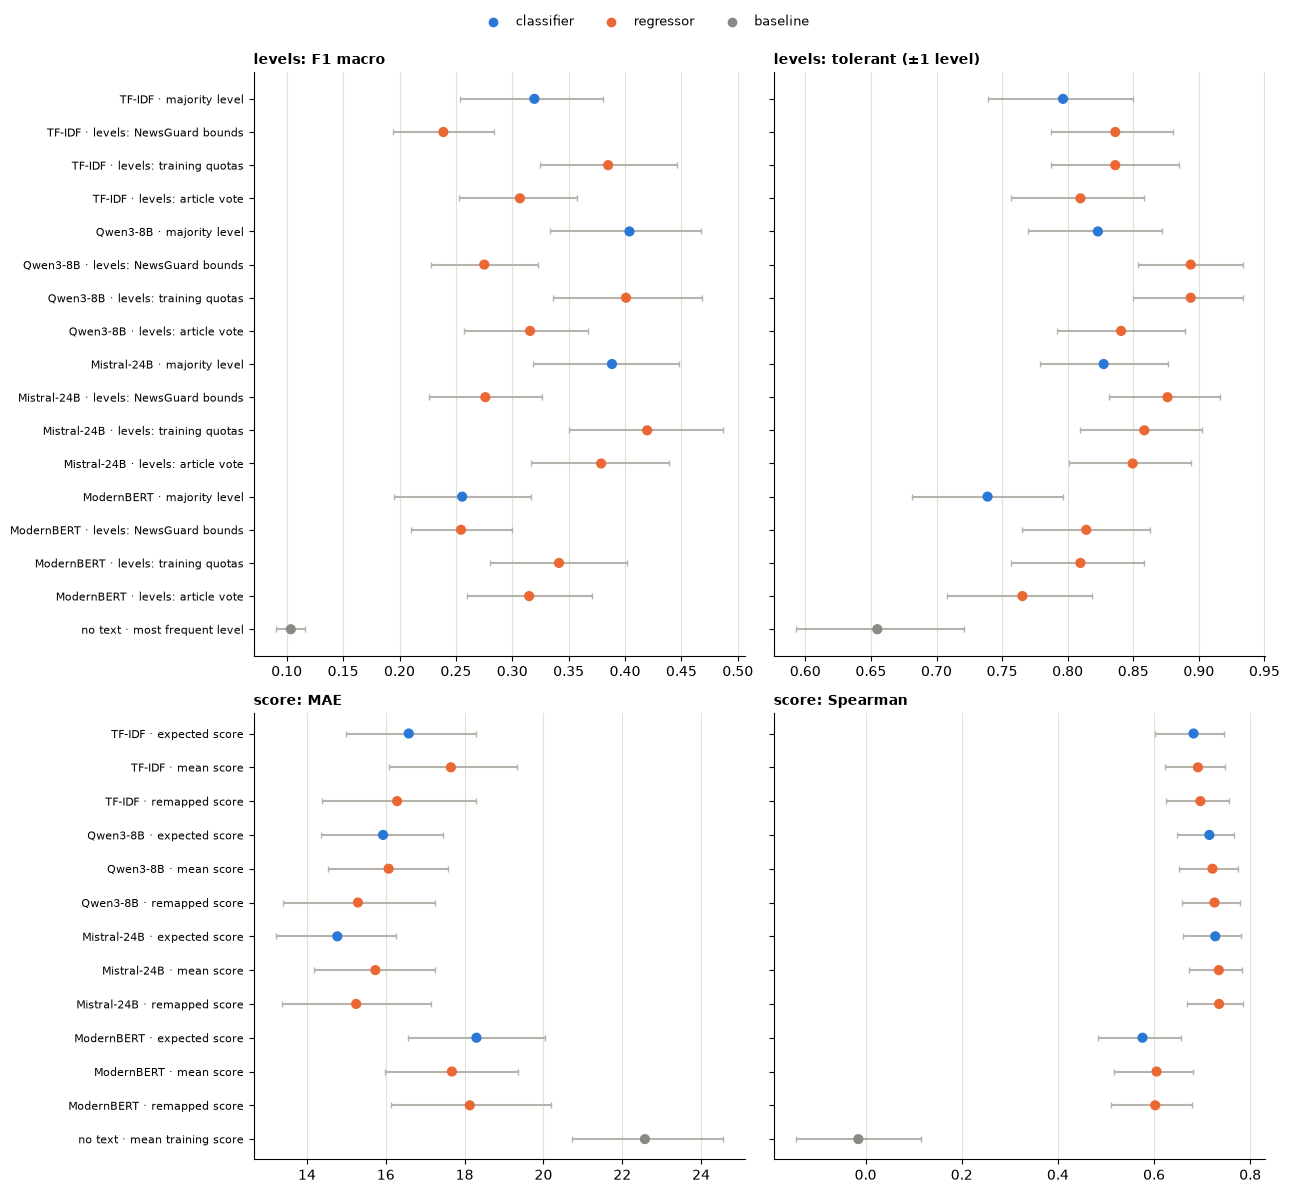

In [7]:
ROWS = [("levels", ["F1 macro", "tolerant (±1 level)"]), ("score", ["MAE", "Spearman"])]
COLOUR = {"classifier": "#2a78d6", "regressor": "#eb6834", "baseline": "#8a8983"}
n = [intervals[intervals.space == s].groupby(["model", "view"]).ngroups for s, _ in ROWS]
fig, axes = plt.subplots(2, 2, figsize=(13, 0.32 * sum(n) + 2), gridspec_kw={"height_ratios": n})
for r, (space, metrics) in enumerate(ROWS):
    for c, metric in enumerate(metrics):
        ax, d = axes[r, c], intervals[(intervals.space == space) & (intervals.metric == metric)].reset_index(drop=True)
        y = np.arange(len(d))
        ax.errorbar(d.value, y, xerr=[d.value - d.low, d.high - d.value], fmt="none", ecolor="#b5b3ab", lw=1.5, capsize=2)
        ax.scatter(d.value, y, s=40, c=[COLOUR[a] for a in d.approach], zorder=3)
        ax.set_yticks(y, [f"{m} · {v}" for m, v in zip(d.model, d.view)] if c == 0 else [""] * len(y), fontsize=8)
        ax.invert_yaxis(); ax.set_title(f"{space}: {metric}", fontsize=10, loc="left", fontweight="bold")
        ax.grid(axis="x", color="#e1e0d9"); ax.spines[["top", "right"]].set_visible(False)
for a, col in COLOUR.items():
    axes[0, 0].scatter([], [], c=col, label=a)
fig.legend(loc="upper center", ncol=3, fontsize=9, frameon=False, bbox_to_anchor=(0.5, 1.03))
plt.tight_layout(); plt.savefig(C.OUT / "results.png", dpi=150, bbox_inches="tight"); plt.show()

## In short

In [8]:
def best(space, metric, lower=False):
    d = all_metrics[(all_metrics.space == space) & (all_metrics.approach != "baseline")]
    r = d.loc[d[metric].idxmin() if lower else d[metric].idxmax()]
    base = all_metrics[(all_metrics.space == space) & (all_metrics.approach == "baseline")][metric].iloc[0]
    return f"- {space}, {metric}: {r.model} ({r.approach}, {r.view}) = {r[metric]:.3f}; without text {base:.3f}"


print("\n".join([best("levels", "F1 macro"), best("levels", "tolerant (±1 level)"), best("levels", "Spearman"),
                 best("score", "MAE", lower=True), best("score", "Spearman"), best("score", "within 10 points")]))
print(f"classifier/regressor differences that are not chance: {pairs['not chance'].sum()} of {len(pairs)}")

- levels, F1 macro: Mistral-24B (regressor, levels: training quotas) = 0.420; without text 0.104
- levels, tolerant (±1 level): Qwen3-8B (regressor, levels: NewsGuard bounds) = 0.894; without text 0.655
- levels, Spearman: Qwen3-8B (regressor, levels: training quotas) = 0.716; without text nan
- score, MAE: Mistral-24B (classifier, expected score) = 14.769; without text 22.575
- score, Spearman: Mistral-24B (regressor, remapped score) = 0.735; without text -0.015
- score, within 10 points: Qwen3-8B (regressor, remapped score) = 0.447; without text 0.181
classifier/regressor differences that are not chance: 31 of 100
